# Exploratory Data Analysis: PowerCo SME Customer Churn

**Goal:** understand the client and price data and see which factors might relate to customers churning, before building features and a model.

**Data:** `client_data.csv` (14,606 SME customers, 26 columns, including the `churn` flag) and `price_data.csv` (193,002 monthly price records for 2015).

**Contents:** 1. Load and inspect, 2. Helper functions, 3. Churn and consumption overview, 4. Data cleaning checks, 5. Churn rate and distributions, 6. Outliers and churn vs. features, 7. Price trends, then key takeaways.

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

In [4]:
client_df = pd.read_csv('./client_data.csv')
price_df = pd.read_csv('./price_data.csv')

## 1. Load and inspect

In [5]:
client_df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0


In [6]:
price_df.head(3)

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0


In [7]:
client_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              14606 non-null  str    
 1   channel_sales                   14606 non-null  str    
 2   cons_12m                        14606 non-null  int64  
 3   cons_gas_12m                    14606 non-null  int64  
 4   cons_last_month                 14606 non-null  int64  
 5   date_activ                      14606 non-null  str    
 6   date_end                        14606 non-null  str    
 7   date_modif_prod                 14606 non-null  str    
 8   date_renewal                    14606 non-null  str    
 9   forecast_cons_12m               14606 non-null  float64
 10  forecast_cons_year              14606 non-null  int64  
 11  forecast_discount_energy        14606 non-null  float64
 12  forecast_meter_rent_12m         14606 non-n

In [8]:
price_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  193002 non-null  str    
 1   price_date          193002 non-null  str    
 2   price_off_peak_var  193002 non-null  float64
 3   price_peak_var      193002 non-null  float64
 4   price_mid_peak_var  193002 non-null  float64
 5   price_off_peak_fix  193002 non-null  float64
 6   price_peak_fix      193002 non-null  float64
 7   price_mid_peak_fix  193002 non-null  float64
dtypes: float64(6), str(2)
memory usage: 19.5 MB


In [9]:
client_df.describe()

,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_off_peak,forecast_price_energy_peak,forecast_price_pow_off_peak,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,pow_max,churn
count,1.460600e+04,1.460600e+04,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000
mean,1.592203e+05,2.809238e+04,16090.269752,1868.614880,1399.762906,0.966726,63.086871,0.137283,0.050491,43.130056,152.786896,24.565121,24.562517,1.292346,189.264522,4.997809,18.135136,0.097152
std,5.734653e+05,1.629731e+05,64364.196422,2387.571531,3247.786255,5.108289,66.165783,0.024623,0.049037,4.485988,341.369366,20.231172,20.230280,0.709774,311.798130,1.611749,13.534743,0.296175
min,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,3.300000,0.000000
25%,5.674750e+03,0.000000e+00,0.000000,494.995000,0.000000,0.000000,16.180000,0.116340,0.000000,40.606701,0.000000,14.280000,14.280000,1.000000,50.712500,4.000000,12.500000,0.000000
50%,1.411550e+04,0.000000e+00,792.500000,1112.875000,314.000000,0.000000,18.795000,0.143166,0.084138,44.311378,37.395000,21.640000,21.640000,1.000000,112.530000,5.000000,13.856000,0.000000
75%,4.076375e+04,0.000000e+00,3383.000000,2401.790000,1745.750000,0.000000,131.030000,0.146348,0.098837,44.311378,193.980000,29.880000,29.880000,1.000000,243.097500,6.000000,19.172500,0.000000
max,6.207104e+06,4.154590e+06,771203.000000,82902.830000,175375.000000,30.000000,599.310000,0.273963,0.195975,59.266378,15042.790000,374.640000,374.640000,32.000000,24570.650000,13.000000,320.000000,1.000000


In [10]:
price_df.describe()

,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
count,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000
mean,0.141027,0.054630,0.030496,43.334477,10.622875,6.409984
std,0.025032,0.049924,0.036298,5.410297,12.841895,7.773592
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.125976,0.000000,0.000000,40.728885,0.000000,0.000000
50%,0.146033,0.085483,0.000000,44.266930,0.000000,0.000000
75%,0.151635,0.101673,0.072558,44.444710,24.339581,16.226389
max,0.280700,0.229788,0.114102,59.444710,36.490692,17.458221


## 2. Helper plotting functions

In [11]:
def plot_stacked_bars(dataframe, title_, size_=(18, 10), rot_=0, legend_="upper right"):
    """
    Plot stacked bars with annotations
    """
    ax = dataframe.plot(
        kind="bar",
        stacked=True,
        figsize=size_,
        rot=rot_,
        title=title_
    )

    # Annotate bars
    annotate_stacked_bars(ax, textsize=14)
    # Rename legend
    plt.legend(["Retention", "Churn"], loc=legend_)
    # Labels
    plt.ylabel("Company base (%)")
    plt.show()

def annotate_stacked_bars(ax, pad=0.99, colour="white", textsize=13):
    """
    Add value annotations to the bars
    """

    # Iterate over the plotted rectanges/bars
    for p in ax.patches:

        # Calculate annotation
        value = str(round(p.get_height(),1))
        # If value is 0 do not annotate
        if value == '0.0':
            continue
        ax.annotate(
            value,
            ((p.get_x()+ p.get_width()/2)*pad-0.05, (p.get_y()+p.get_height()/2)*pad),
            color=colour,
            size=textsize
        )

def plot_distribution(dataframe, column, ax, bins_=50):
    """
    Plot variable distirbution in a stacked histogram of churned or retained company
    """
    # Create a temporal dataframe with the data to be plot
    temp = pd.DataFrame({"Retention": dataframe[dataframe["churn"]==0][column],
    "Churn":dataframe[dataframe["churn"]==1][column]})
    # Plot the histogram
    temp[["Retention","Churn"]].plot(kind='hist', bins=bins_, ax=ax, stacked=True)
    # X-axis label
    ax.set_xlabel(column)
    # Change the x-axis to plain style
    ax.ticklabel_format(style='plain', axis='x')

## 3. Churn and consumption overview

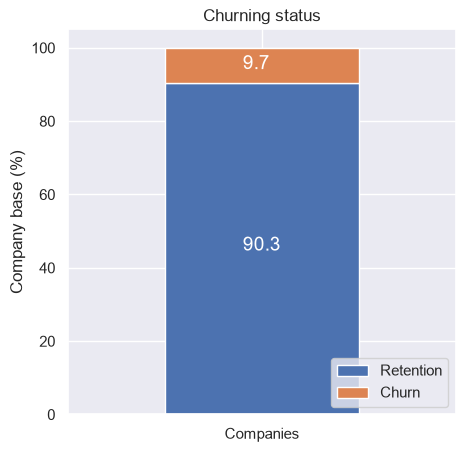

In [12]:
churn = client_df[['id', 'churn']]
churn.columns = ['Companies', 'churn']
churn_total = churn.groupby(churn['churn']).count()
churn_percentage = churn_total / churn_total.sum() * 100
plot_stacked_bars(churn_percentage.transpose(), "Churning status", (5, 5), legend_="lower right")

**Finding: churn status**
- Roughly **9.7% of customers churned** (about 90% retained), the same imbalance confirmed in the churn-rate section below.

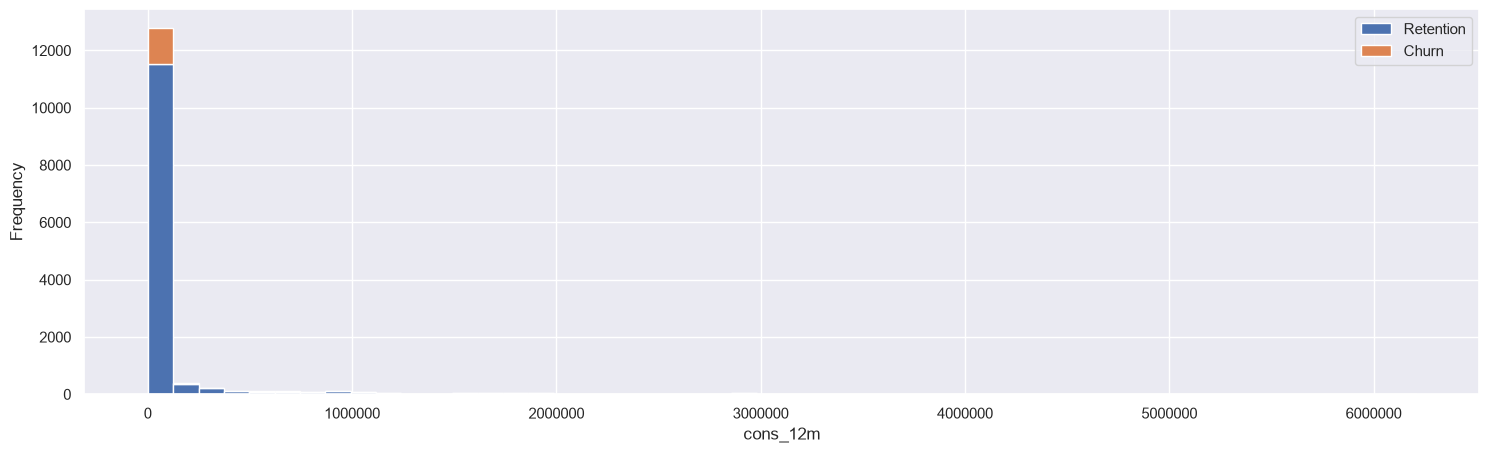

In [13]:
consumption = client_df[['id', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'imp_cons', 'has_gas', 'churn']]

fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'cons_12m', axs)

**Finding: consumption**
- Yearly electricity use (`cons_12m`) is extremely right-skewed: most customers use a modest amount, while a thin tail runs up to ~6.2 million.
- Churned and retained customers overlap almost completely in this histogram, so raw consumption alone does not separate them.

## 4. Data cleaning checks

In [17]:
# ============================================================
# 1. FIX DATE COLUMNS — Convert object → datetime
# ============================================================

date_cols = ['date_activ', 'date_end', 'date_modif_prod', 'date_renewal']

for col in date_cols:
    client_df[col] = pd.to_datetime(client_df[col], errors='coerce')

price_df['price_date'] = pd.to_datetime(price_df['price_date'], errors='coerce')

print("Updated dtypes for date columns:")
print(client_df[date_cols].dtypes)

Updated dtypes for date columns:
date_activ         datetime64[us]
date_end           datetime64[us]
date_modif_prod    datetime64[us]
date_renewal       datetime64[us]
dtype: object


**Data prep:** the four date columns and `price_date` were converted from text to datetime so tenure, contract-end and price-trend analysis can use them.

In [18]:
# ============================================================
# 2. MISSING VALUES CHECK
# ============================================================

print("=== Missing values in client_df ===")
print(client_df.isnull().sum())

print("\n=== Missing values in price_df ===")
print(price_df.isnull().sum())

# Also check for placeholder 'MISSING' strings in object columns
print("\n=== 'MISSING' string counts in client_df object columns ===")
for col in client_df.columns:
    if not (client_df[col].dtype == 'object' or pd.api.types.is_string_dtype(client_df[col])):
        continue
    count = (client_df[col] == 'MISSING').sum()
    if count > 0:
        print(f"  {col}: {count} 'MISSING' values")

=== Missing values in client_df ===
id                                0
channel_sales                     0
cons_12m                          0
cons_gas_12m                      0
cons_last_month                   0
date_activ                        0
date_end                          0
date_modif_prod                   0
date_renewal                      0
forecast_cons_12m                 0
forecast_cons_year                0
forecast_discount_energy          0
forecast_meter_rent_12m           0
forecast_price_energy_off_peak    0
forecast_price_energy_peak        0
forecast_price_pow_off_peak       0
has_gas                           0
imp_cons                          0
margin_gross_pow_ele              0
margin_net_pow_ele                0
nb_prod_act                       0
net_margin                        0
num_years_antig                   0
origin_up                         0
pow_max                           0
churn                             0
dtype: int64

=== Missing va

**Finding: missing values**
- There are **no nulls** in either table, but missing data is hidden behind a `'MISSING'` placeholder: `channel_sales` has **3,725** such rows (about 25% of customers) and `origin_up` has 64.
- These need to be treated as their own category, not dropped. Missing sales channel may itself carry information.

## 5. Churn rate and distributions

=== Churn Distribution ===
  Not churned (0): 13187 (90.3%)
  Churned    (1): 1419 (9.7%)


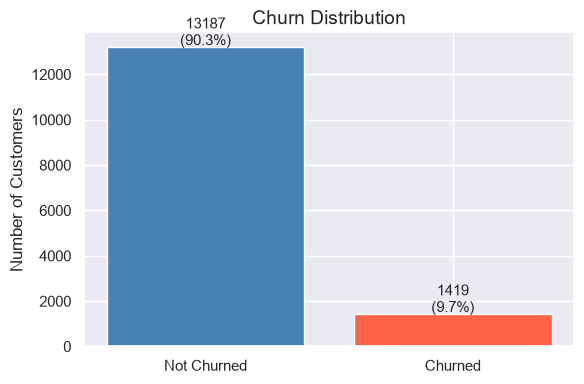

In [19]:
# ============================================================
# 3. CHURN RATE ANALYSIS
# ============================================================

churn_counts = client_df['churn'].value_counts()
churn_pct = client_df['churn'].value_counts(normalize=True) * 100

print("=== Churn Distribution ===")
print(f"  Not churned (0): {churn_counts[0]} ({churn_pct[0]:.1f}%)")
print(f"  Churned    (1): {churn_counts[1]} ({churn_pct[1]:.1f}%)")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['Not Churned', 'Churned'], churn_counts.values, color=['steelblue', 'tomato'])
ax.set_title('Churn Distribution', fontsize=14)
ax.set_ylabel('Number of Customers')
for i, v in enumerate(churn_counts.values):
    ax.text(i, v + 100, f'{v}\n({churn_pct.values[i]:.1f}%)', ha='center', fontsize=11)
plt.tight_layout()
plt.show()

**Finding: churn rate**
- **1,419 of 14,606 customers (9.7%) churned**, so the classes are imbalanced roughly 9:1.
- Accuracy would be misleading on this data (predicting "no churn" for everyone already scores about 90%). Later modelling should use class weights and judge the model with ROC-AUC, precision and recall.

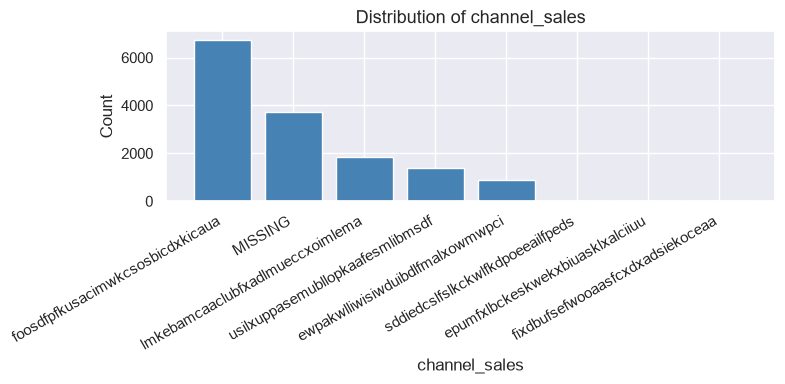


Value counts for channel_sales:
channel_sales
foosdfpfkusacimwkcsosbicdxkicaua    6754
MISSING                             3725
lmkebamcaaclubfxadlmueccxoimlema    1843
usilxuppasemubllopkaafesmlibmsdf    1375
ewpakwlliwisiwduibdlfmalxowmwpci     893
sddiedcslfslkckwlfkdpoeeailfpeds      11
epumfxlbckeskwekxbiuasklxalciiuu       3
fixdbufsefwooaasfcxdxadsiekoceaa       2
Name: count, dtype: int64



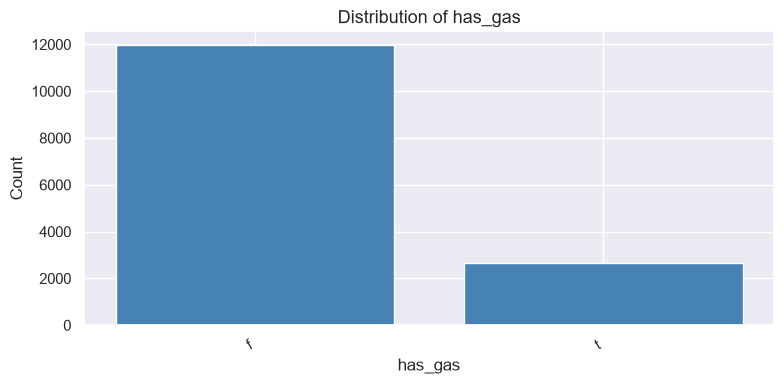


Value counts for has_gas:
has_gas
f    11955
t     2651
Name: count, dtype: int64



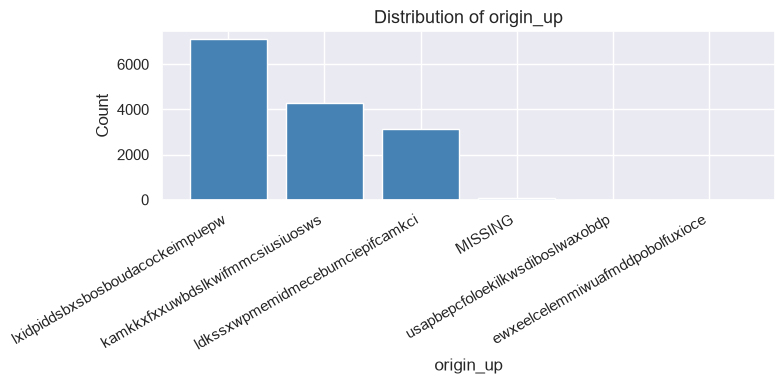


Value counts for origin_up:
origin_up
lxidpiddsbxsbosboudacockeimpuepw    7097
kamkkxfxxuwbdslkwifmmcsiusiuosws    4294
ldkssxwpmemidmecebumciepifcamkci    3148
MISSING                               64
usapbepcfoloekilkwsdiboslwaxobdp       2
ewxeelcelemmiwuafmddpobolfuxioce       1
Name: count, dtype: int64



In [20]:
# ============================================================
# 4. CATEGORICAL COLUMN DISTRIBUTIONS
# ============================================================

cat_cols = ['channel_sales', 'has_gas', 'origin_up']

for col in cat_cols:
    fig, ax = plt.subplots(figsize=(8, 4))
    value_counts = client_df[col].value_counts()
    ax.bar(value_counts.index, value_counts.values, color='steelblue')
    ax.set_title(f'Distribution of {col}', fontsize=13)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()
    print(f"\nValue counts for {col}:")
    print(value_counts)
    print()

**Finding: categorical columns**
- **`channel_sales`:** one channel dominates (6,754 customers, about 46%), 3,725 are `MISSING`, and three channels have only 2 to 11 customers each, too few to learn from.
- **`has_gas`:** only about 18% of customers (2,651) also buy gas.
- **`origin_up`:** three origins cover almost everyone (7,097, 4,294 and 3,148); the rest are `MISSING` (64) or have just 1 to 2 customers.
- Rare categories can be grouped into an "other" bucket before encoding. The segment table further below shows churn rates for each group.

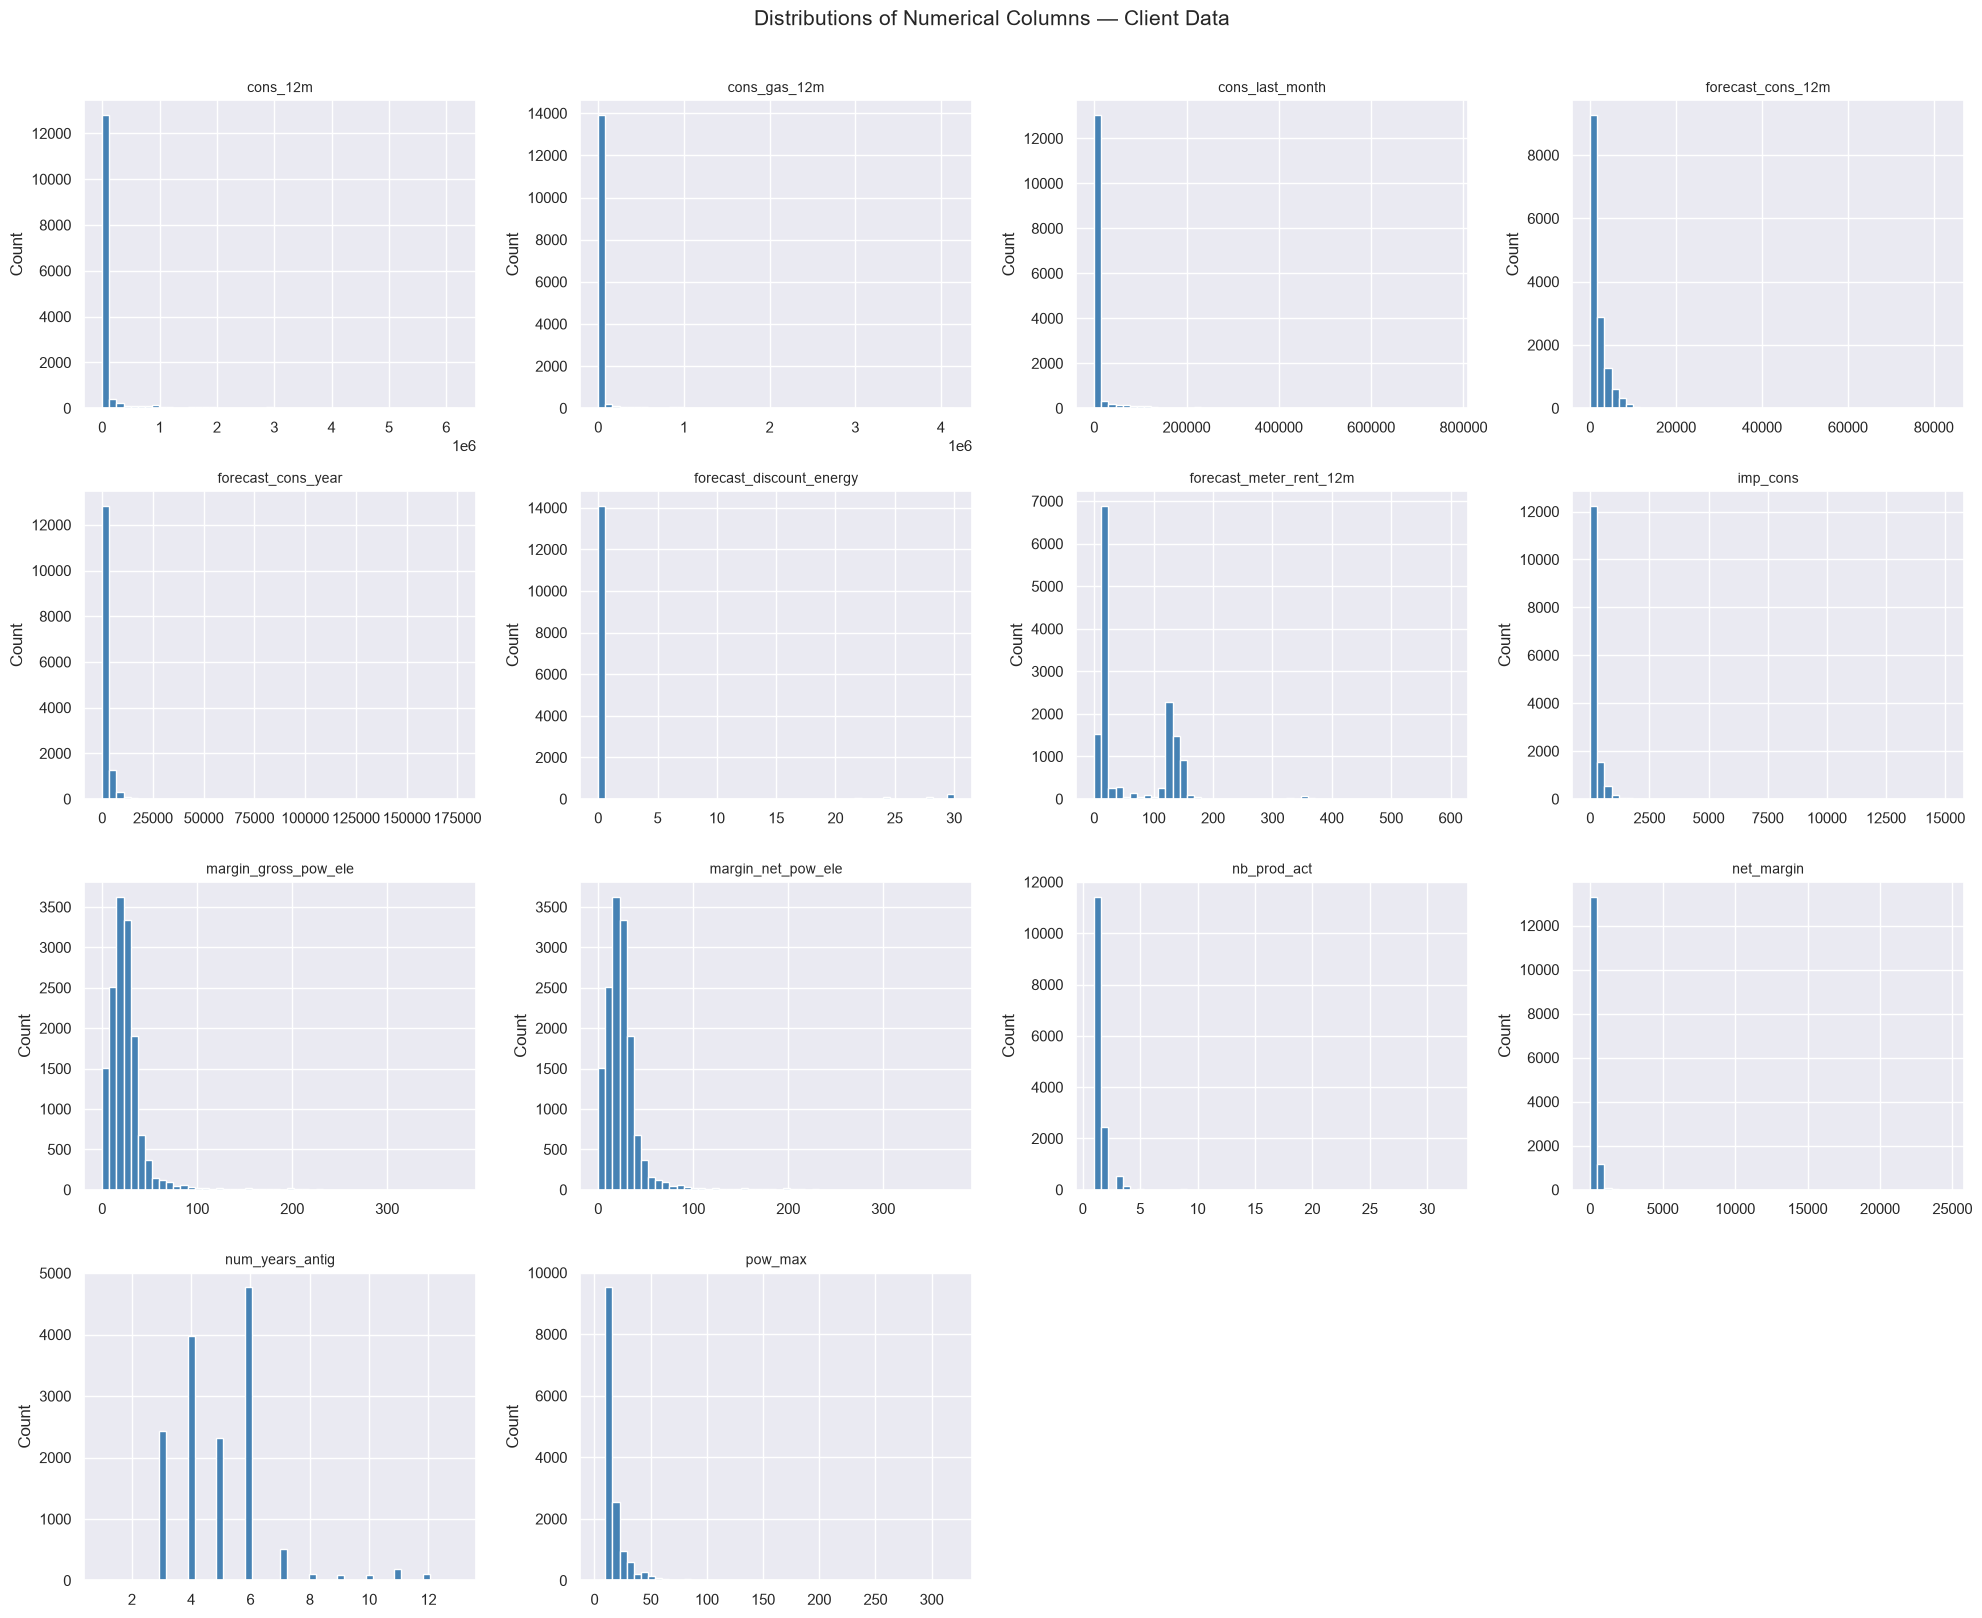

In [21]:
# ============================================================
# 5. NUMERICAL COLUMN DISTRIBUTIONS — CLIENT DATA
# ============================================================

num_cols_client = [
    'cons_12m', 'cons_gas_12m', 'cons_last_month',
    'forecast_cons_12m', 'forecast_cons_year',
    'forecast_discount_energy', 'forecast_meter_rent_12m',
    'imp_cons', 'margin_gross_pow_ele', 'margin_net_pow_ele',
    'nb_prod_act', 'net_margin', 'num_years_antig', 'pow_max'
]

fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(20, 16))
axes = axes.flatten()

for i, col in enumerate(num_cols_client):
    axes[i].hist(client_df[col].dropna(), bins=50, color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

# Hide unused subplots
for j in range(len(num_cols_client), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Distributions of Numerical Columns — Client Data', fontsize=15, y=1.01)
plt.tight_layout()
plt.show()

**Finding: client numerical distributions**
- Almost every variable is heavily right-skewed (for example `net_margin`, `imp_cons`, `forecast_cons_12m`), with a few very large customers stretching the axes.
- Many columns are mostly zeros: about **82%** of customers have no gas consumption, **42%** have `imp_cons` of 0, **34%** had zero consumption last month, and **96%** have no forecast discount.
- About **78%** of customers hold a single active product (`nb_prod_act` = 1), and tenure (`num_years_antig`) is centred on about 5 years.
- Implication: log transforms or tree-based models will handle this better than methods that assume a normal distribution.

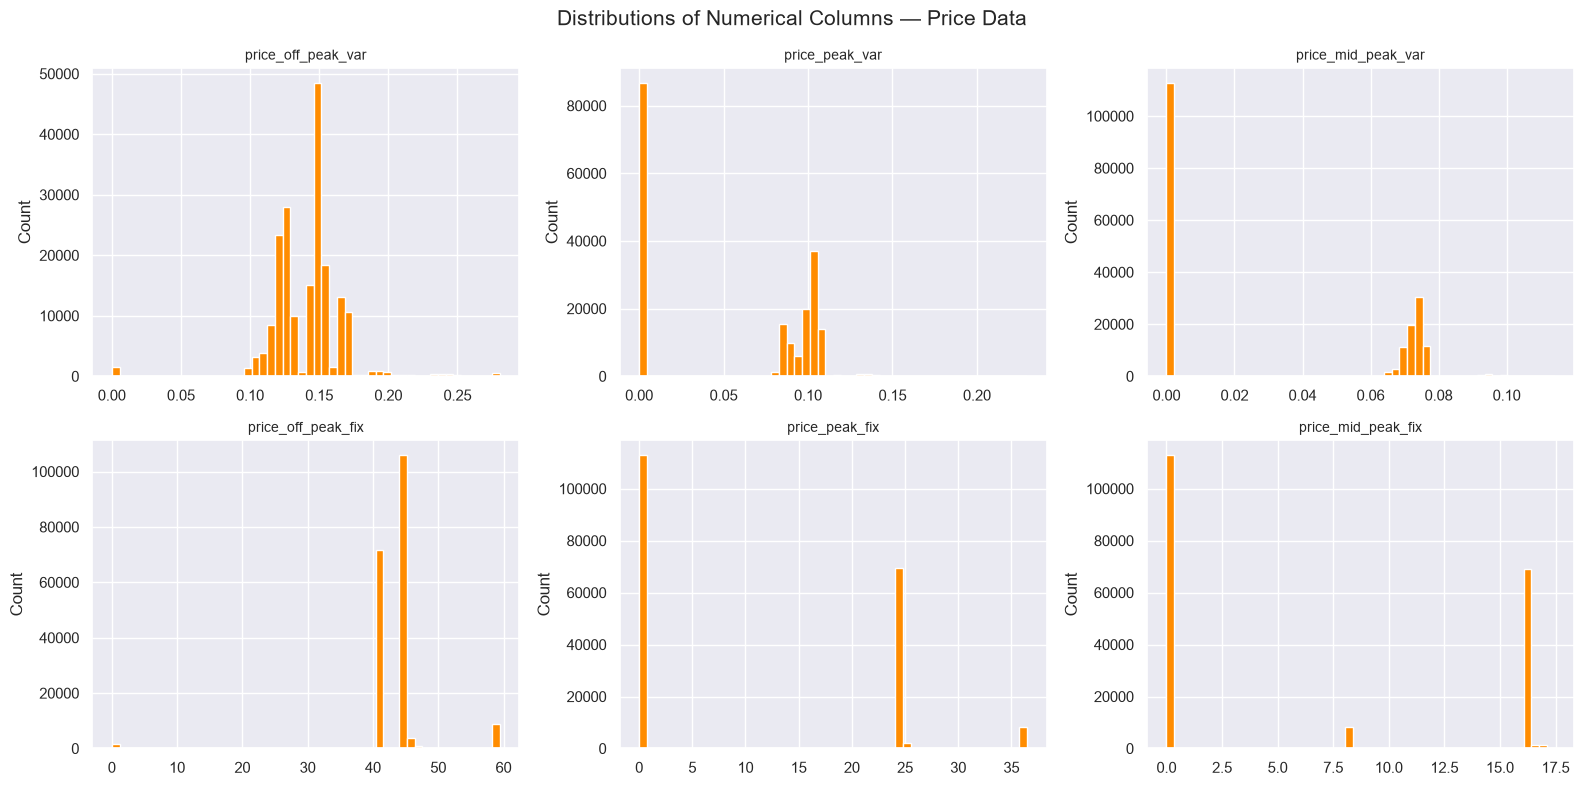

In [22]:
# ============================================================
# 6. NUMERICAL COLUMN DISTRIBUTIONS — PRICE DATA
# ============================================================

num_cols_price = [
    'price_off_peak_var', 'price_peak_var', 'price_mid_peak_var',
    'price_off_peak_fix', 'price_peak_fix', 'price_mid_peak_fix'
]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(num_cols_price):
    axes[i].hist(price_df[col].dropna(), bins=50, color='darkorange', edgecolor='white')
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylabel('Count')

plt.suptitle('Distributions of Numerical Columns — Price Data', fontsize=15)
plt.tight_layout()
plt.show()

**Finding: price distributions**
- Off-peak prices are almost always present, but **peak and mid-peak prices are zero in about 45% and 58% of rows**, meaning many customers are not billed in those periods.
- Off-peak variable prices sit mostly between 0.13 and 0.15, and off-peak fixed prices cluster around 40 to 44, so most customers pay very similar rates.
- Zeros here are structural (tariff type), not missing data, and should not be imputed.

## 6. Outliers and churn vs. features

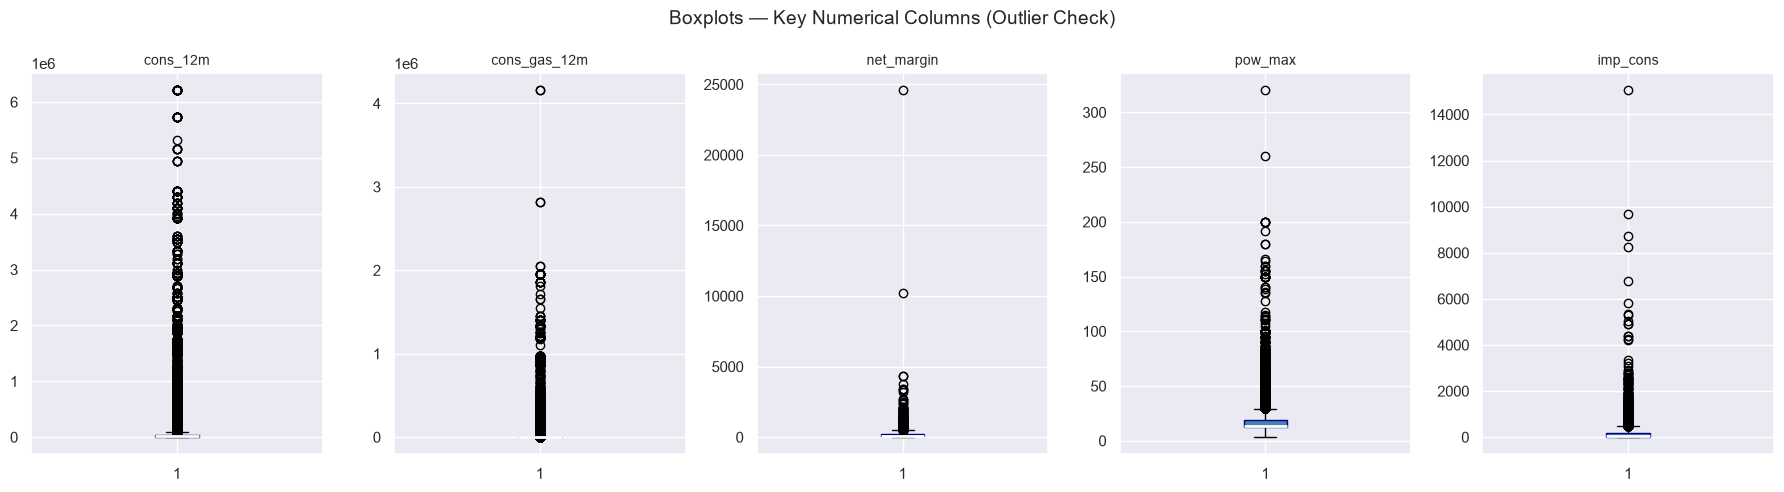

In [23]:
# ============================================================
# 7. BOXPLOTS — SPOT OUTLIERS IN KEY COLUMNS
# ============================================================

outlier_cols = ['cons_12m', 'cons_gas_12m', 'net_margin', 'pow_max', 'imp_cons']

fig, axes = plt.subplots(nrows=1, ncols=len(outlier_cols), figsize=(18, 5))

for i, col in enumerate(outlier_cols):
    axes[i].boxplot(client_df[col].dropna(), patch_artist=True,
                    boxprops=dict(facecolor='steelblue', color='navy'),
                    medianprops=dict(color='white', linewidth=2))
    axes[i].set_title(col, fontsize=10)

plt.suptitle('Boxplots — Key Numerical Columns (Outlier Check)', fontsize=14)
plt.tight_layout()
plt.show()

**Finding: outliers**
- The gaps between typical and extreme values are huge: `cons_12m` has a median of about 14,000 against a maximum of 6.2 million, `net_margin` a median of about 112 against a maximum of about 24,600, and `pow_max` a median of about 14 against a maximum of 320.
- These look like a small number of very large business customers rather than data errors, so they are candidates for log transformation or capping instead of deletion.

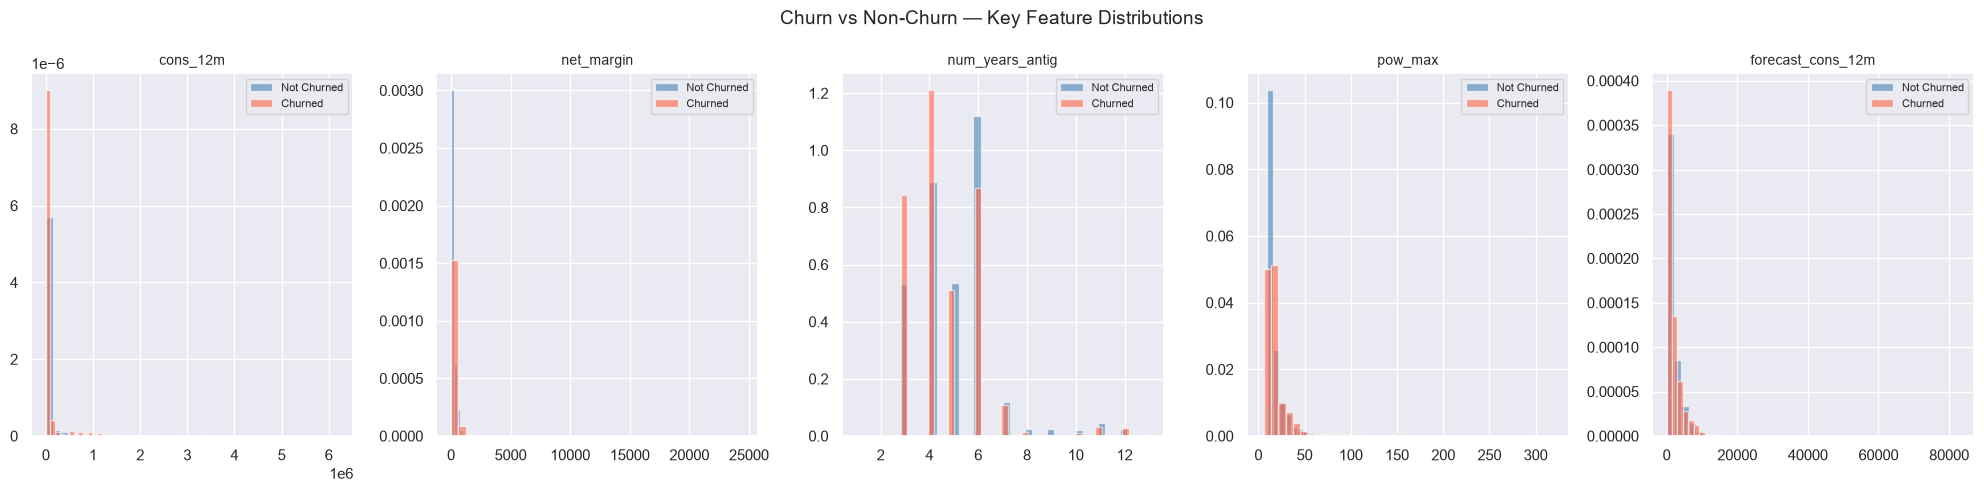

In [24]:
# ============================================================
# 8. CHURN vs KEY NUMERICAL FEATURES — COMPARE DISTRIBUTIONS
# ============================================================

churn_compare_cols = ['cons_12m', 'net_margin', 'num_years_antig', 'pow_max', 'forecast_cons_12m']

fig, axes = plt.subplots(nrows=1, ncols=len(churn_compare_cols), figsize=(20, 5))

for i, col in enumerate(churn_compare_cols):
    churned = client_df[client_df['churn'] == 1][col].dropna()
    not_churned = client_df[client_df['churn'] == 0][col].dropna()
    axes[i].hist(not_churned, bins=40, alpha=0.6, color='steelblue', label='Not Churned', density=True)
    axes[i].hist(churned, bins=40, alpha=0.6, color='tomato', label='Churned', density=True)
    axes[i].set_title(col, fontsize=10)
    axes[i].legend(fontsize=8)

plt.suptitle('Churn vs Non-Churn — Key Feature Distributions', fontsize=14)
plt.tight_layout()
plt.show()

**Finding: churn vs. non-churn**
- For `cons_12m`, `forecast_cons_12m`, `pow_max` and `net_margin`, the churned and retained distributions **nearly overlap**. Their medians are almost the same (for example `cons_12m` about 14.1k vs 14.5k and `pow_max` 13.856 for both).
- **Tenure is the exception:** churners have a lower median `num_years_antig` (4 years vs 5), so newer customers leave more often.
- No single customer-size variable explains churn on its own, which suggests that combinations of features and price behaviour matter more.

### Churn rate by segment

In [ ]:
# Churn rate by segment (supports the findings above)
for col in ['channel_sales', 'origin_up', 'has_gas']:
    print(client_df.groupby(col)['churn']
          .agg(churn_rate='mean', customers='size')
          .sort_values('customers', ascending=False).round(3), '\n')

tenure = pd.cut(client_df['num_years_antig'], [0, 3, 5, 7, 20],
                labels=['1-3 yrs', '4-5 yrs', '6-7 yrs', '8+ yrs'])
print(client_df.groupby(tenure, observed=True)['churn']
      .agg(churn_rate='mean', customers='size').round(3), '\n')

cons_quartile = pd.qcut(client_df['cons_12m'].rank(method='first'), 4,
                        labels=['Q1 (lowest)', 'Q2', 'Q3', 'Q4 (highest)'])
print(client_df.groupby(cons_quartile, observed=True)['churn']
      .agg(churn_rate='mean', customers='size').round(3))

**Finding: churn by segment**
- **Tenure has a clear gradient:** churn falls from about **13.6%** for customers with 1 to 3 years to about **5.8%** for those with 8+ years.
- **Origin and sales channel matter:** the largest origin (`lxidp...`) churns at about 12.6% versus about 6.0% for `kamkk...`. The largest channel (`foosdf...`) churns at about 12.1% versus about 5.6% for `lmkeb...`.
- **Gas customers churn slightly less** (about 8.2% vs 10.1%).
- **Consumption quartiles are flat** (about 9.3% to 10.0%), confirming that customer size is not a strong churn signal.

## 7. Price trends

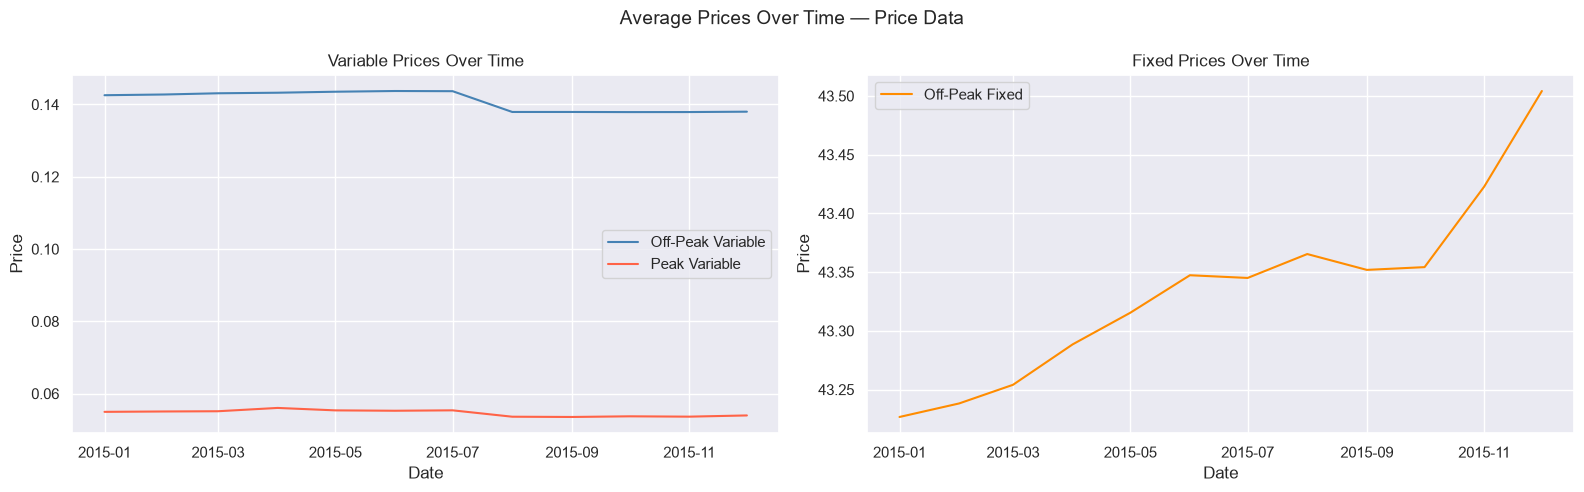

In [25]:
# ============================================================
# 9. PRICE TRENDS OVER TIME
# ============================================================

price_over_time = price_df.groupby('price_date')[
    ['price_off_peak_var', 'price_peak_var', 'price_off_peak_fix']
].mean().reset_index()

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 5))

axes[0].plot(price_over_time['price_date'], price_over_time['price_off_peak_var'],
             label='Off-Peak Variable', color='steelblue')
axes[0].plot(price_over_time['price_date'], price_over_time['price_peak_var'],
             label='Peak Variable', color='tomato')
axes[0].set_title('Variable Prices Over Time')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Price')
axes[0].legend()

axes[1].plot(price_over_time['price_date'], price_over_time['price_off_peak_fix'],
             label='Off-Peak Fixed', color='darkorange')
axes[1].set_title('Fixed Prices Over Time')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Price')
axes[1].legend()

plt.suptitle('Average Prices Over Time — Price Data', fontsize=14)
plt.tight_layout()
plt.show()

**Finding: price trends over 2015**
- Average prices are fairly stable across the year. The off-peak variable price falls about **4% in August 2015** (0.1437 to 0.1379) and stays flat afterwards. The peak variable price follows the same pattern but with a smaller step (0.0554 to 0.0536).
- The off-peak fixed price creeps up steadily, from about 43.23 to 43.50 (roughly +0.6%).
- Because average changes are small, any price effect on churn is likely concentrated in specific customers, which is why customer-level price-change features (Dec vs Jan, 6-month and yearly changes) are built later.
- Note: the price table contains **16,096 customer ids vs 14,606 in the client table**, so it must be filtered to matching clients before merging.

## Key takeaways

1. Churn is **9.7%** (1,419 of 14,606 customers), a clearly imbalanced target.
2. Data quality: no nulls, but 25% of `channel_sales` is a `'MISSING'` placeholder, and many price and consumption columns are mostly structural zeros.
3. Most numerical features are heavily skewed with large outliers (log transforms / tree models).
4. **Tenure, sales channel and origin** show the clearest differences in churn; customer size (consumption) does not.
5. Average prices barely move over 2015, so price features should be built per customer rather than from market averages.

**Next step:** feature engineering (see `02_feature_engineering.ipynb`).